# Spectral Embedding, Clustering & Peak Calling

In [1]:
import gatac as ga
import scanpy as sc
import rapids_singlecell as rsc
import anndata as ad
import time

sc.set_figure_params(dpi=100, frameon=False)

adata = ad.read_h5ad("data/pbmc_tile.h5ad")
print(adata)

AnnData object with n_obs × n_vars = 5001 × 6062095
    obs: 'barcode', 'n_unique', 'tsse_score', 'duplicate_fraction', 'mito_fraction'
    var: 'chrom', 'start', 'end', 'selected', 'accessibility_count'


## 1. Spectral embedding

Compute a spectral decomposition of the TF-IDF-normalised cell × tile matrix.
The resulting components are stored in `adata.obsm["X_spectral"]`.

In [2]:
t0 = time.perf_counter()
ga.tl.spectral(adata, n_comps=30)
print(f"Spectral embedding in {time.perf_counter() - t0:.1f}s")
print(f"Embedding shape: {adata.obsm['X_spectral'].shape}")

15:20:49 - gatac.tl.spectral - INFO - Running GPU-accelerated spectral embedding ...
15:20:51 - gatac.tl.spectral - INFO - IDF weights computed.
15:20:51 - gatac.tl.spectral - INFO - Row normalization done.
15:20:51 - gatac.tl.spectral - INFO - Eigen-decomposition done.
15:20:51 - gatac.tl.spectral - INFO - Spectral embedding complete: 30 components (top eigenvalue = 1.0000).


Spectral embedding in 1.9s
Embedding shape: (5001, 30)


## 2. UMAP & Leiden clustering

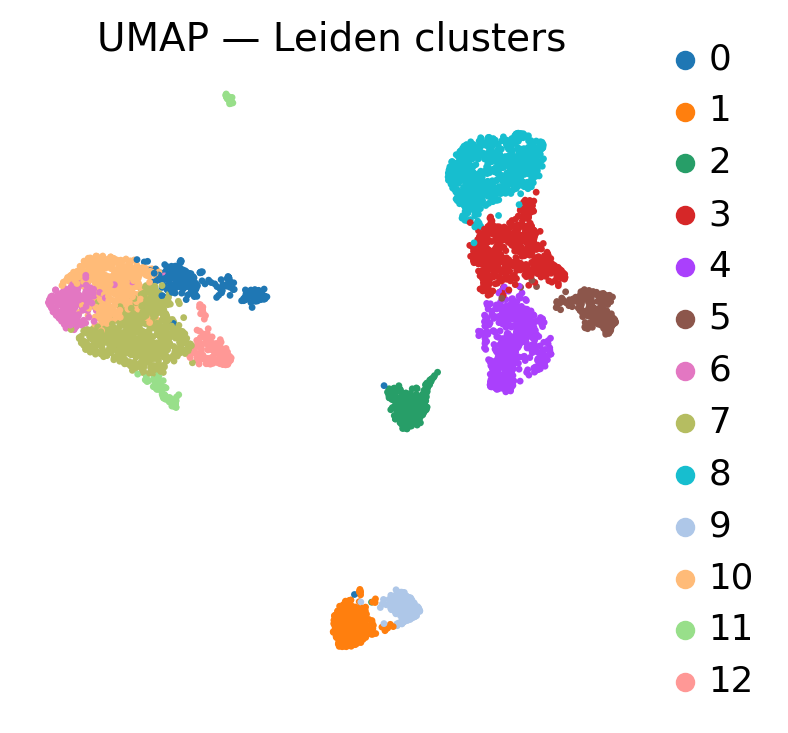

In [3]:
rsc.pp.neighbors(adata, use_rep="X_spectral", n_neighbors=30)
rsc.tl.umap(adata, min_dist=0.3)
rsc.tl.leiden(adata, resolution=0.5)

sc.pl.umap(adata, color="leiden",
           title="UMAP — Leiden clusters")

## 3. Call peaks per cluster

We are running for each Leiden cluster a gpu accelerated implementation of MACS3 (gmacs).

In [4]:
t0 = time.perf_counter()
ga.tl.call_peaks(
    adata,
    groupby="leiden",
    parquet_path="data/pbmc_fragments.parquet",
    genome="hg38",
)
print(f"Peak calling in {time.perf_counter() - t0:.1f}s")

15:21:05 - gatac.tl.peaks - INFO - Using genome length: 3,088,269,832 bp
15:21:05 - gatac.tl.peaks - INFO - Calling peaks for 13 groups in 'leiden'


Groups:   0%|          | 0/13 [00:00<?, ?it/s]

15:21:05 - gatac.tl.peaks - INFO - Processing group: 5
15:21:08 - gatac.tl.peaks - INFO -   5,000,812 fragments, calling peaks...
15:21:30 - gatac.tl.peaks - INFO -   Found 45,079 peaks
15:21:31 - gatac.tl.peaks - INFO - Processing group: 4
15:21:33 - gatac.tl.peaks - INFO -   9,778,471 fragments, calling peaks...
15:21:56 - gatac.tl.peaks - INFO -   Found 56,580 peaks
15:21:56 - gatac.tl.peaks - INFO - Processing group: 6
15:21:58 - gatac.tl.peaks - INFO -   3,703,051 fragments, calling peaks...
15:22:20 - gatac.tl.peaks - INFO -   Found 70,325 peaks
15:22:20 - gatac.tl.peaks - INFO - Processing group: 8
15:22:22 - gatac.tl.peaks - INFO -   9,735,768 fragments, calling peaks...
15:22:45 - gatac.tl.peaks - INFO -   Found 52,531 peaks
15:22:45 - gatac.tl.peaks - INFO - Processing group: 3
15:22:47 - gatac.tl.peaks - INFO -   9,769,370 fragments, calling peaks...
15:23:09 - gatac.tl.peaks - INFO -   Found 53,840 peaks
15:23:10 - gatac.tl.peaks - INFO - Processing group: 9
15:23:11 - gata

Peak calling in 314.3s


In [5]:
# Number of peaks per cluster
for group, peak_df in adata.uns["gmacs"].items():
    print(f"  Cluster {group}: {len(peak_df):,} peaks")


  Cluster 5: 45,079 peaks
  Cluster 4: 56,580 peaks
  Cluster 6: 70,325 peaks
  Cluster 8: 52,531 peaks
  Cluster 3: 53,840 peaks
  Cluster 9: 53,778 peaks
  Cluster 1: 60,363 peaks
  Cluster 12: 71,171 peaks
  Cluster 7: 100,060 peaks
  Cluster 10: 80,956 peaks
  Cluster 11: 77,834 peaks
  Cluster 0: 71,424 peaks
  Cluster 2: 56,955 peaks


## 4. Merge peaks across clusters

In [6]:
ga.tl.merge_peaks(adata,chrom_sizes="hg38")
adata.uns["peaks"]

,chrom,start,end,name,score,strand,signal_value,p_value,q_value,peak
171986,chr1,778385,778886,.,1000,.,18.646694,1000.000000,1000.000000,250
45085,chr1,827219,827720,.,1000,.,22.037284,1000.000000,1000.000000,250
171990,chr1,869638,870139,.,1000,.,32.572115,1000.000000,1000.000000,250
463684,chr1,959011,959512,.,1000,.,20.804989,1000.000000,1000.000000,250
463694,chr1,1013132,1013633,.,1000,.,20.022753,1000.000000,1000.000000,250
...,...,...,...,...,...,...,...,...,...,...
742801,chr14,66718232,66718733,.,13,.,3.048780,3.278076,1.328900,250
743289,chr14,79501649,79502150,.,13,.,3.048780,3.278076,1.328900,250
755741,chr19,32997620,32998121,.,13,.,3.048780,3.278076,1.328900,250
776568,chr5,118732321,118732822,.,13,.,3.048780,3.278076,1.328900,250


## 5. Build cell × peak matrix

In [7]:
t0 = time.perf_counter()
peak_adata = ga.tl.make_peak_matrix(
    adata,parquet_path="data/pbmc_fragments.parquet",
)
print(f"Peak matrix built in {time.perf_counter() - t0:.1f}s")
print(peak_adata)

15:26:48 - gatac.tl.peaks - INFO - Counting fragments in 178,350 peaks
15:26:48 - gatac.tl.peaks - INFO - Processing single parquet file


Parquet files:   0%|          | 0/1 [00:00<?, ?it/s]

15:26:59 - gatac.pp.gene - INFO - Using uint8 dtype (max count: 70)
15:26:59 - gatac.tl.peaks - INFO - Peak matrix: 5,001 cells × 178,350 peaks
15:26:59 - gatac.tl.peaks - INFO - Sparsity: 95.17%


Peak matrix built in 11.2s
AnnData object with n_obs × n_vars = 5001 × 178350
    obs: 'barcode', 'n_unique', 'tsse_score', 'duplicate_fraction', 'mito_fraction', 'leiden'


## 6. Save

In [8]:
peak_adata.write_h5ad("data/pbmc_peaks.h5ad")
print("Saved → data/pbmc_peaks.h5ad")

Saved → data/pbmc_peaks.h5ad


## Next steps

- [03 – Motif enrichment](03_motif_enrichment.ipynb)
- [04 – chromVAR](04_chromvar.ipynb)